In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df=pd.read_csv("~/Machine Learning/100 days of Machine Learning/Standardization (Z-score Normalization)/Datasets/Social_Network_Ads.csv")

In [5]:
df.sample(5)

,User ID,Gender,Age,EstimatedSalary,Purchased
21,15736760,Female,47,49000,1
220,15789432,Female,41,80000,0
156,15791174,Male,46,59000,0
69,15595324,Female,31,68000,0
377,15800215,Female,42,53000,0


In [7]:
df.drop(columns=['User ID','Gender'],inplace=True)

In [8]:
df.sample(5)

,Age,EstimatedSalary,Purchased
283,52,21000,1
7,32,150000,1
311,39,96000,1
361,53,34000,1
173,34,43000,0


### Train Test Split

In [9]:
from sklearn.model_selection import train_test_split

In [11]:
X_train,X_test,Y_train,Y_test=train_test_split(df.drop(columns='Purchased'),df['Purchased'],test_size=0.3,random_state=0) 
#random_state=0 — a seed for the random number generator. This makes the split reproducible — every time you run this code, 
#you'll get the exact same split. Without it, the split would be random each time you ran the code.

In [14]:
X_train.shape,X_test.shape

((280, 2), (120, 2))

### Scaling

In [65]:
from sklearn.preprocessing import StandardScaler

scaler=StandardScaler()

#fit is applied to only training data not test data
#fit just learn statistics and store it in the scaler object, we can use fit_transform function too for doing both in one step
scaler.fit(X_train)

#transformation is applied to both training and test data
x_train_scaled=scaler.transform(X_train)
x_test_scaled=scaler.transform(X_test)

In [19]:
x_train_scaled

array([[-1.1631724 , -1.5849703 ],
       [ 2.17018137,  0.93098672],
       [ 0.0133054 ,  1.22017719],
       [ 0.20938504,  1.07558195],
       [ 0.40546467, -0.48604654],
       [-0.28081405, -0.31253226],
       [ 0.99370357, -0.8330751 ],
       [ 0.99370357,  1.8563962 ],
       [ 0.0133054 ,  1.24909623],
       [-0.86905295,  2.26126285],
       [-1.1631724 , -1.5849703 ],
       [ 2.17018137, -0.80415605],
       [-1.35925203, -1.46929411],
       [ 0.40546467,  2.2901819 ],
       [ 0.79762394,  0.75747245],
       [-0.96709276, -0.31253226],
       [ 0.11134522,  0.75747245],
       [-0.96709276,  0.55503912],
       [ 0.30742485,  0.06341534],
       [ 0.69958412, -1.26686079],
       [-0.47689368, -0.0233418 ],
       [-1.7514113 ,  0.3526058 ],
       [-0.67297331,  0.12125343],
       [ 0.40546467,  0.29476771],
       [-0.28081405,  0.06341534],
       [-0.47689368,  2.2901819 ],
       [ 0.20938504,  0.03449629],
       [ 1.28782302,  2.20342476],
       [ 0.79762394,

In [68]:
x_train_scaled=pd.DataFrame(x_train_scaled,columns=X_train.columns)
x_test_scaled=pd.DataFrame(x_test_scaled,columns=X_test.columns)

In [23]:
x_train_scaled

,Age,EstimatedSalary
0,-1.163172,-1.584970
1,2.170181,0.930987
2,0.013305,1.220177
3,0.209385,1.075582
4,0.405465,-0.486047
...,...,...
275,0.993704,-1.151185
276,-0.869053,-0.775237
277,-0.182774,-0.514966
278,-1.065133,-0.457127


In [26]:
np.round(x_train_scaled.describe()),np.round(X_train.describe())

(         Age  EstimatedSalary
 count  280.0            280.0
 mean     0.0              0.0
 std      1.0              1.0
 min     -2.0             -2.0
 25%     -1.0             -1.0
 50%     -0.0              0.0
 75%      1.0              1.0
 max      2.0              2.0,
          Age  EstimatedSalary
 count  280.0            280.0
 mean    38.0          69807.0
 std     10.0          34641.0
 min     18.0          15000.0
 25%     30.0          43000.0
 50%     37.0          70500.0
 75%     46.0          88000.0
 max     60.0         150000.0)

### Plotting 

<Axes: xlabel='Age', ylabel='EstimatedSalary'>

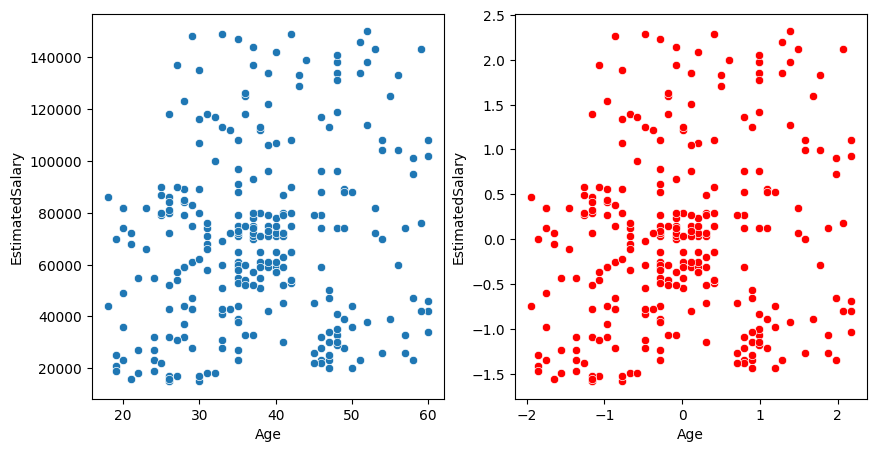

In [43]:
fig,axes=plt.subplots(1,2,figsize=(10,5))
sns.scatterplot(data=X_train,x='Age',y='EstimatedSalary',ax=axes[0])
sns.scatterplot(data=x_train_scaled,x='Age',y='EstimatedSalary',ax=axes[1],color='red')
# both are exactly same except the scale

Text(0.5, 1.0, 'After Scaling')

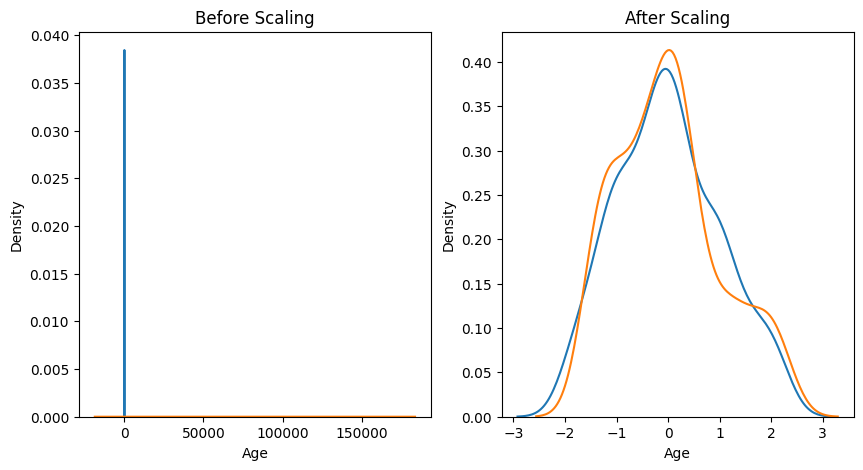

In [51]:
fig,axes=plt.subplots(1,2,figsize=(10,5))
sns.kdeplot(data=X_train,x='Age',ax=axes[0])
sns.kdeplot(data=X_train,x='EstimatedSalary',ax=axes[0])
axes[0].set_title('Before Scaling')

sns.kdeplot(data=x_train_scaled,x='Age',ax=axes[1])
sns.kdeplot(data=x_train_scaled,x='EstimatedSalary',ax=axes[1])
axes[1].set_title("After Scaling

#after scaling the curves are comparable

### Effects of outliers
outliers effect the Z-score normalization in a destructive way

In [53]:
df.describe()

,Age,EstimatedSalary,Purchased
count,400.000000,400.000000,400.000000
mean,37.655000,69742.500000,0.357500
std,10.482877,34096.960282,0.479864
min,18.000000,15000.000000,0.000000
25%,29.750000,43000.000000,0.000000
50%,37.000000,70000.000000,0.000000
75%,46.000000,88000.000000,1.000000
max,60.000000,150000.000000,1.000000


In [54]:
df

,Age,EstimatedSalary,Purchased
0,19,19000,0
1,35,20000,0
2,26,43000,0
3,27,57000,0
4,19,76000,0
...,...,...,...
395,46,41000,1
396,51,23000,1
397,50,20000,1
398,36,33000,0


In [63]:
new_df=[{"Age":100,"EstimatedSalary":112,"Purchased":0},{"Age":2,"EstimatedSalary":19000000,"Purchased":1},{"Age":109,"EstimatedSalary":1009,"Purchased":1}]
new_df=pd.DataFrame(new_df)
df=pd.concat([df,new_df])

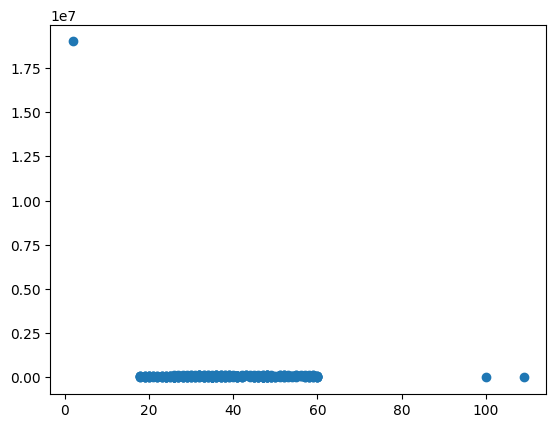

In [70]:
plt.scatter(df['Age'], df['EstimatedSalary'])